# 🔬 The "No-Calculus" Guide to ODEs in PhosphoKineticSolver

## 1. The Molecule Bank Account

Imagine each state in our 8-state hypercube (like $S_{000}$ or $S_{111}$) is a bank account. 
- **Deposits (Inflow):** Rates at which reactions feed molecules *into* this state.
- **Withdrawals (Outflow):** Rates at which reactions drain molecules *out* of this state.

The derivative `ds/dt` is simply your net balance change per second:
$$\text{Net Change} = \text{Inflow} - \text{Outflow}$$

In [1]:
# Quick Python demonstration of a single-state accounting ledger
def mock_ledger(s_current, k_in, k_out):
    """Calculates ds/dt as simple molecular accounting."""
    inflow = k_in * (1.0 - s_current)
    outflow = k_out * s_current
    ds_dt = inflow - outflow
    return ds_dt


print(
    f"Net rate of change for current concentration 0.2: {mock_ledger(0.2, 0.5, 0.1):.3f}")

Net rate of change for current concentration 0.2: 0.380


## 2. Stepping Forward in Time

Computers can't jump straight from $t = 0$ to $t = 100$. Instead, `solve_ivp` acts like a time-lapse camera, taking tiny micro-steps ($\Delta t$) and asking: 
*"Given my current concentration and my rate ledger rules, where will I be one micro-second from now?"*

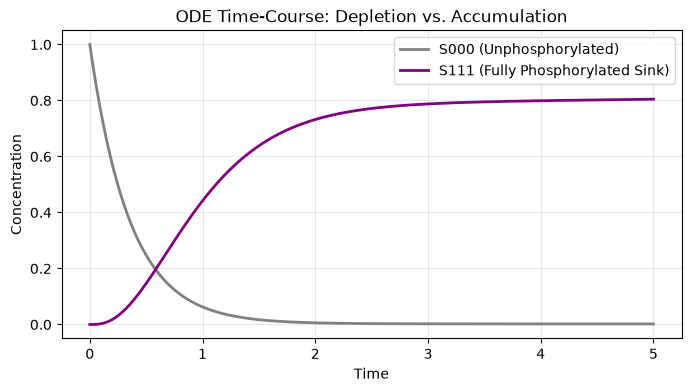

In [5]:
import numpy as np
import matplotlib.pyplot as plt
from polarity_engine.kinetics import PhosphoKineticSolver

# Minimal setup to run a baseline simulation
graphs = {code: None for code in ['000', '100', '010', '001', '110', '101', '011', '111']}
solver = PhosphoKineticSolver(graphs=graphs, site_mappings={}, regime="processive")

t, y = solver.simulate(t_span=(0, 5))

# Quick plot of Unphosphorylated (S000) vs Fully Phosphorylated Sink (S111)
plt.figure(figsize=(8, 4))
plt.plot(t, y[0], label='S000 (Unphosphorylated)', color='gray', linewidth=2)
plt.plot(t, y[7], label='S111 (Fully Phosphorylated Sink)', color='purple', linewidth=2)
plt.xlabel('Time')
plt.ylabel('Concentration')
plt.title('ODE Time-Course: Depletion vs. Accumulation')
plt.legend()
plt.grid(True, alpha=0.3)
plt.show()

## 3. Interactive Sandbox: Toggling Regimes & Alpha

Use the interactive sliders below to see how tweaking structural gating (`alpha`) or switching between **processive** and **dissociative** regimes warps the phosphorylation trajectories in real time!

**About $\alpha$**  
The parameter $\alpha$ acts as an exponential gain controller for how aggressively structural accessibility (rSASA) warps the baseline kinetic rates:
- If $\alpha = 0.0$:  
    - Structural rSASA is completely ignored, and every state defaults to its flat Tier 1 baseline rate.
- If $\alpha$ is very large (e.g., $5.0$):  
    - Even minor shifts in surface exposure create massive, unrealistic rate cliffs, causing the ODE solver to become overly sensitive to subtle coordinate noise in the PDB structures.
- At $\alpha = 1.2$:  
    - A fully exposed residue ($\text{rSASA} \approx 1.0$) receives an acceleration factor of $\exp(1.2 \times 1.0) \approx 3.32\text{x}$. This provides a biologically meaningful modulation window—allowing surface exposure to meaningfully enhance phosphorylation without completely overriding the core enzymatic hierarchy established by the bulk assays.

**About multiplier values**  
Multi-site phosphorylation enzymes generally operate under one of two operating regimes when adding multiple phosphates:  
- The Processive Regime (Multiplier = 2.5):  
    - *Mechanism*: 
        - Once aPKC-Par6 binds to Lgl, it phosphorylates an initial site (e.g., Site 3) and—without letting go of the substrate—pivots or slides along the structure to phosphorylate adjacent sites ($S_{110}$, $S_{101}$, etc.).  
    - *Why the boost?*  
        - Because the enzyme doesn't have to diffuse back into the bulk solution and find a new substrate molecule, the local effective concentration remains extremely high. The multiplier 2.5 accelerates downstream intermediate-to-sink transitions, modeling this structural hand-off efficiency.  
- The Dissociative / Distributive Regime (Multiplier = 0.4):
    - *Mechanism*:  
        - The kinase phosphorylates one site, completely unbinds and diffuses away into the cytoplasm, and then must randomly re-encounter the partially phosphorylated substrate to add the next phosphate.
    - *Why the penalty?*  
        - Diffusion limits, unfavorable re-binding orientation, and loss of local tethering introduce a kinetic drag. The multiplier 0.4 penalizes downstream progression, slowing down sequential multi-site accumulation.

In [6]:
import ipywidgets as widgets
from IPython.display import display

def run_interactive_simulation(alpha_val, regime_choice):
    # Instantiate solver with widget inputs
    interactive_solver = PhosphoKineticSolver(
        graphs=graphs, 
        site_mappings={}, 
        alpha=alpha_val, 
        regime=regime_choice
    )
    t_sim, y_sim = interactive_solver.simulate(t_span=(0, 5))
    
    plt.figure(figsize=(9, 4))
    plt.plot(t_sim, y_sim[0], label='S000', color='gray', linestyle='--')
    plt.plot(t_sim, y_sim[7], label='S111 (Sink)', color='crimson', linewidth=2.5)
    plt.ylim(-0.05, 1.05)
    plt.xlabel('Time')
    plt.ylabel('Concentration')
    plt.title(f'Regime: {regime_choice.upper()} | Alpha: {alpha_val}')
    plt.legend()
    plt.grid(True, alpha=0.3)
    plt.show()

# Bind widgets
widgets.interact(
    run_interactive_simulation,
    alpha_val=widgets.FloatSlider(value=1.2, min=0.0, max=3.0, step=0.1, description='Alpha:'),
    regime_choice=widgets.Dropdown(options=['processive', 'dissociative'], value='processive', description='Regime:')
);

interactive(children=(FloatSlider(value=1.2, description='Alpha:', max=3.0), Dropdown(description='Regime:', o…

## 4. Bridging 3D Structure to Kinetics (rSASA Gating)

An ODE model is only as good as its parameters. In `PhosphoKineticSolver`, we don't just guess static rates—we pull real structural context from **PyTorch Geometric (PyG) graphs** generated upstream by Nextflow (`ALIGN_CIF`).

### How It Works:
1. **`site_mapping.json`**: Acts as our dictionary, translating functional biology (e.g., *"Site 3 is Serine 138"*) into exact structural node indices.
2. **Feature Index 22**: In our PyG node feature tensor (`graph.x`), index `22` holds the Relative Solvent Accessible Surface Area (**rSASA**).
3. **The Gating Multiplier**: Exposure enhances phosphorylation:
   $$\text{Multiplier} = \exp(\alpha \cdot \text{rSASA})$$

In [ ]:
import torch
import numpy as np

# Simulate a mock PyG Data object graph for state '000'
# Imagine a small protein graph with 150 nodes, where node 138 has an rSASA of 0.85 (highly exposed)
mock_node_features = torch.zeros((150, 25))
mock_node_features[138, 22] = 0.85  # Feature index 22 = rSASA

mock_graphs = {'000': type('MockGraph', (), {'x': mock_node_features})()}
mock_site_mappings = {'site_3': {'res_num': 138, 'consensus_label': 'Ser664'}}

# Test the solver's internal rSASA lookup
solver = PhosphoKineticSolver(
    graphs=mock_graphs, 
    site_mappings=mock_site_mappings, 
    alpha=1.2, 
    regime="processive"
)

# Calculate the rate multiplier for Site 3
multiplier = solver._compute_rate_multiplier('000', 'site_3')
print(f"Site 3 rSASA: {mock_node_features[138, 22].item():.2f}")
print(f"Computed Rate Multiplier (exp(alpha * rSASA)): {multiplier:.3f}x boost")

Site 3 rSASA: 0.85
Computed Rate Multiplier (exp(alpha * rSASA)): 2.773x boost


### Why This Matters for the Hypercube
When Site 3 is surface-exposed ($\text{rSASA} \approx 0.85$), its entry rate is scaled upward, making it the preferred entry gateway into the hypercube ($S_{000} \to S_{001}$). If a structural mutation or conformational shift buries Site 3 ($\text{rSASA} \approx 0.0$), the multiplier drops back to `1.0`, disabling that kinetic highway and forcing the kinase to explore secondary entry pathways instead!